# RQ7 — When does increased ESM2 capacity improve functional generalization?

## Scientific question

**Within the same pretrained protein-language-model family, when does moving from ESM2-T6 (8M parameters) to ESM2-T30 (150M parameters) provide meaningful additional generalization, and when is the smaller model already sufficient?**

This is a **within-family capacity contrast**, not a general neural scaling law.

The comparison is especially clean because T6 and T30 are evaluated using exactly the same:

\[
\text{task}\times R\times S\times\text{algorithm}
\]

benchmark cells.

### Frozen representations

- `esm2_t6_8m`: ESM2-T6, ~8M parameters, 320-dimensional pooled embedding.
- `esm2_t30_150m`: ESM2-T30, ~150M parameters, 640-dimensional pooled embedding.

Thus T30 has substantially greater pretrained model capacity and a larger embedding dimension. The benchmark can determine whether this **larger ESM2 representation** improves downstream generalization, but it cannot isolate model parameter count from every architectural difference between the two variants.

## RQ7 scope

The notebook answers only the high-value questions:

1. How large and consistent is `T30 − T6`?
2. Which biological tasks benefit most?
3. Where is T6 already practically sufficient?
4. Does the T30 advantage increase under stricter redundancy reduction?
5. Does it increase under stricter train–test homology separation?
6. Does T30 improve worst-case generalization?
7. Does increased ESM2 capacity reduce sensitivity to R and S?
8. Is the gain mainly explained by baseline headroom / task saturation?
9. Are conclusions preserved with AP skill and multiclass macro-F1?
10. Where does T6 actually outperform T30?

No compute-efficiency analysis is performed here. No mechanistic claim is made about what biological features the larger PLM learned.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 300)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 300)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]

T6 = "esm2_t6_8m"
T30 = "esm2_t30_150m"

BINARY_TASKS = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
]

PRACTICAL_TIE = 0.01
SUBSTANTIAL_GAIN = 0.05

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)

    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_supervised/stage12a").is_dir()
            and (candidate / "results/analysis_supervised/stage12b").is_dir()
        ):
            return candidate

    raise FileNotFoundError(
        "Could not locate project root containing Stage12A and Stage12B."
    )

ROOT = find_project_root()
STAGE12A = ROOT / "results/analysis_supervised/stage12a"
STAGE12B = ROOT / "results/analysis_supervised/stage12b"
CACHE_DIR = ROOT / "results/analysis_supervised/notebook_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)

ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass


In [2]:
master = pd.read_csv(
    STAGE12A / "supervised_master_results.tsv",
    sep="\t",
    low_memory=False,
)

plm = master[
    master["representation"].isin([T6, T30])
].copy()

print("Total supervised families:", len(master))
print("T6/T30 families:", len(plm))
print("Tasks:", sorted(plm["task"].unique()))
print("Algorithms:", sorted(plm["algorithm"].unique()))

coverage = (
    plm.groupby(["task", "R", "S", "algorithm"])
    ["representation"]
    .nunique()
    .rename("n_representations")
    .reset_index()
)

display(
    coverage["n_representations"]
    .value_counts()
    .sort_index()
    .to_frame("n_matched_cells")
)

assert coverage["n_representations"].eq(2).all(), (
    "One or more benchmark cells do not contain both T6 and T30."
)

N_MATCHED = len(coverage)
print("Matched T6/T30 benchmark cells:", N_MATCHED)
assert N_MATCHED == 560, f"Expected 560 matched cells, found {N_MATCHED}."

Total supervised families: 2240
T6/T30 families: 1120
Tasks: ['global_easy', 'global_hard', 'global_mixed', 'multiclass_clean', 'subtype_depolymerase', 'subtype_endolysin', 'subtype_val']
Algorithms: ['KNN', 'LR', 'MLP', 'RF', 'XGB']


,n_matched_cells
n_representations,
2,560


Matched T6/T30 benchmark cells: 560


# 1. Prevalence-normalized AP skill

In [3]:
def detect_prevalence(df):
    for c in [
        "test_prevalence",
        "prevalence",
        "positive_prevalence",
        "class_prevalence",
    ]:
        if c in df.columns:
            return pd.to_numeric(df[c], errors="coerce"), c

    if {"n_positive", "n_test"} <= set(df.columns):
        return (
            pd.to_numeric(df["n_positive"], errors="coerce")
            / pd.to_numeric(df["n_test"], errors="coerce")
        ), "derived_from_n_positive_n_test"

    if {"tp", "fn", "tn", "fp"} <= set(df.columns):
        pos = (
            pd.to_numeric(df["tp"], errors="coerce")
            + pd.to_numeric(df["fn"], errors="coerce")
        )
        n = (
            pos
            + pd.to_numeric(df["tn"], errors="coerce")
            + pd.to_numeric(df["fp"], errors="coerce")
        )
        return pos / n, "derived_from_confusion_counts"

    return pd.Series(np.nan, index=df.index), None

prev, prev_source = detect_prevalence(plm)
plm["prevalence_for_ap"] = prev

if "ap" in plm.columns:
    denom = 1.0 - plm["prevalence_for_ap"]
    plm["ap_skill"] = np.where(
        denom > 0,
        (plm["ap"] - plm["prevalence_for_ap"]) / denom,
        np.nan,
    )

print("Prevalence source:", prev_source)

Prevalence source: prevalence


# 2. Build the exact matched T30 − T6 table

In [4]:
def build_t30_t6_pairs(df, metric):
    rows = []

    for keys, grp in df.groupby(
        ["task", "R", "S", "algorithm"]
    ):
        task, r, s, alg = keys

        lookup = dict(
            zip(
                grp["representation"],
                pd.to_numeric(grp[metric], errors="coerce"),
            )
        )

        if (
            T6 not in lookup
            or T30 not in lookup
            or pd.isna(lookup[T6])
            or pd.isna(lookup[T30])
        ):
            continue

        rows.append(
            {
                "task": task,
                "R": int(r),
                "S": int(s),
                "algorithm": alg,
                "metric": metric,
                "T6": float(lookup[T6]),
                "T30": float(lookup[T30]),
                "delta_T30_minus_T6": (
                    float(lookup[T30]) - float(lookup[T6])
                ),
            }
        )

    return pd.DataFrame(rows)

mcc_pairs = build_t30_t6_pairs(plm, "mcc")

print("Matched MCC pairs:", len(mcc_pairs))
assert len(mcc_pairs) == 560

display(mcc_pairs.head())

Matched MCC pairs: 560


,task,R,S,algorithm,metric,T6,T30,delta_T30_minus_T6
0,global_easy,30,30,KNN,mcc,0.756290,0.887662,0.131372
1,global_easy,30,30,LR,mcc,0.698308,0.840543,0.142235
2,global_easy,30,30,MLP,mcc,0.801661,0.877293,0.075631
3,global_easy,30,30,RF,mcc,0.688509,0.831723,0.143214
4,global_easy,30,30,XGB,mcc,0.782209,0.879389,0.097180


# 3. Global capacity benefit

In [5]:
d = mcc_pairs["delta_T30_minus_T6"]

global_gain = pd.DataFrame(
    {
        "n": [len(d)],
        "mean_delta": [d.mean()],
        "median_delta": [d.median()],
        "std_delta": [d.std()],
        "q10": [d.quantile(0.10)],
        "q25": [d.quantile(0.25)],
        "q75": [d.quantile(0.75)],
        "q90": [d.quantile(0.90)],
        "min_delta": [d.min()],
        "max_delta": [d.max()],
        "fraction_positive": [(d > 0).mean()],
        "fraction_gt_001": [(d > PRACTICAL_TIE).mean()],
        "fraction_gt_005": [(d > SUBSTANTIAL_GAIN).mean()],
        "fraction_negative": [(d < 0).mean()],
    }
)

display(global_gain)

,n,mean_delta,median_delta,std_delta,q10,q25,q75,q90,min_delta,max_delta,fraction_positive,fraction_gt_001,fraction_gt_005,fraction_negative
0,560,0.084573,0.076907,0.081199,0.003131,0.019407,0.124788,0.171116,-0.086975,0.533816,0.928571,0.828571,0.617857,0.066071


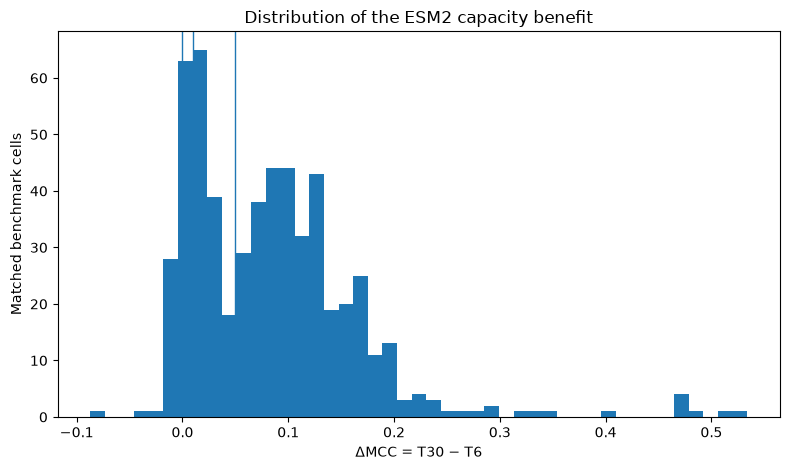

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hist(
    d,
    bins=45,
)
ax.axvline(0, linewidth=1)
ax.axvline(PRACTICAL_TIE, linewidth=1)
ax.axvline(SUBSTANTIAL_GAIN, linewidth=1)
ax.set_xlabel("ΔMCC = T30 − T6")
ax.set_ylabel("Matched benchmark cells")
ax.set_title("Distribution of the ESM2 capacity benefit")
plt.tight_layout()
plt.show()

## Practical benefit regimes

To avoid treating every tiny numerical difference as biologically meaningful:

- `T30 substantial`: ΔMCC > +0.05
- `T30 moderate`: +0.01 < ΔMCC ≤ +0.05
- `practically equivalent`: |ΔMCC| ≤ 0.01
- `T6 better`: ΔMCC < -0.01

These are descriptive practical thresholds, not statistical significance cutoffs.

In [7]:
def classify_capacity_gain(delta):
    if pd.isna(delta):
        return np.nan
    if delta > SUBSTANTIAL_GAIN:
        return "T30_substantial"
    if delta > PRACTICAL_TIE:
        return "T30_moderate"
    if delta >= -PRACTICAL_TIE:
        return "practically_equivalent"
    return "T6_better"

mcc_pairs["capacity_regime"] = (
    mcc_pairs["delta_T30_minus_T6"]
    .map(classify_capacity_gain)
)

display(
    mcc_pairs["capacity_regime"]
    .value_counts(normalize=True)
    .rename("fraction")
    .to_frame()
)

,fraction
capacity_regime,
T30_substantial,0.617857
T30_moderate,0.210714
practically_equivalent,0.151786
T6_better,0.019643


# 4. Which biological tasks benefit from increased ESM2 capacity?

In [8]:
task_gain = (
    mcc_pairs.groupby("task")
    .agg(
        n=("delta_T30_minus_T6", "size"),
        mean_delta=("delta_T30_minus_T6", "mean"),
        median_delta=("delta_T30_minus_T6", "median"),
        q25=("delta_T30_minus_T6", lambda x: x.quantile(0.25)),
        q75=("delta_T30_minus_T6", lambda x: x.quantile(0.75)),
        fraction_positive=(
            "delta_T30_minus_T6",
            lambda x: (x > 0).mean(),
        ),
        fraction_substantial=(
            "delta_T30_minus_T6",
            lambda x: (x > SUBSTANTIAL_GAIN).mean(),
        ),
        fraction_equivalent=(
            "delta_T30_minus_T6",
            lambda x: (x.abs() <= PRACTICAL_TIE).mean(),
        ),
        fraction_T6_better=(
            "delta_T30_minus_T6",
            lambda x: (x < -PRACTICAL_TIE).mean(),
        ),
    )
    .sort_values("median_delta", ascending=False)
)

display(task_gain)

,n,mean_delta,median_delta,q25,q75,fraction_positive,fraction_substantial,fraction_equivalent,fraction_T6_better
task,,,,,,,,,
subtype_endolysin,80,0.132807,0.133600,0.101507,0.166555,1.0000,0.9875,0.0000,0.0000
subtype_val,80,0.164512,0.121127,0.076239,0.225307,0.9375,0.8875,0.0375,0.0250
global_easy,80,0.113703,0.113017,0.090576,0.132414,1.0000,1.0000,0.0000,0.0000
global_mixed,80,0.113086,0.104026,0.087174,0.131464,1.0000,1.0000,0.0000,0.0000
multiclass_clean,80,0.031465,0.030146,0.013258,0.048080,0.9250,0.2250,0.1875,0.0250
subtype_depolymerase,80,0.028987,0.021048,0.005907,0.040129,0.8375,0.2250,0.2750,0.0625
global_hard,80,0.007452,0.007816,0.001139,0.014489,0.8000,0.0000,0.5625,0.0250


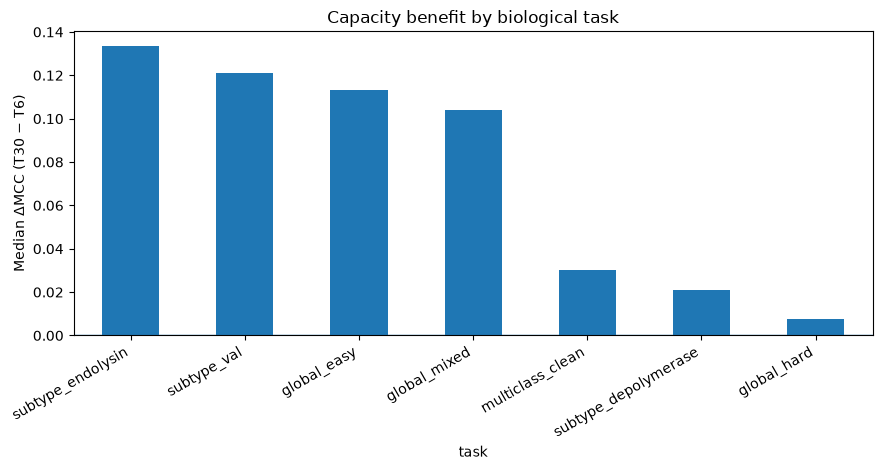

In [9]:
task_gain["median_delta"].plot(
    kind="bar",
    figsize=(9, 4.8),
)
plt.axhline(0, linewidth=1)
plt.ylabel("Median ΔMCC (T30 − T6)")
plt.title("Capacity benefit by biological task")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

A near-zero task-level gain should be interpreted as **T6 sufficiency for this benchmarked task regime**, not as evidence that the larger PLM contains no additional biological information.

# 5. Practical benefit regimes by task

In [10]:
display(
    pd.crosstab(
        mcc_pairs["task"],
        mcc_pairs["capacity_regime"],
        normalize="index",
    )
)

capacity_regime,T30_moderate,T30_substantial,T6_better,practically_equivalent
task,,,,
global_easy,0.0000,1.0000,0.0000,0.0000
global_hard,0.4125,0.0000,0.0250,0.5625
global_mixed,0.0000,1.0000,0.0000,0.0000
multiclass_clean,0.5625,0.2250,0.0250,0.1875
subtype_depolymerase,0.4375,0.2250,0.0625,0.2750
subtype_endolysin,0.0125,0.9875,0.0000,0.0000
subtype_val,0.0500,0.8875,0.0250,0.0375


# 6. Does the downstream learner change the capacity benefit?

In [11]:
alg_gain = (
    mcc_pairs.groupby("algorithm")
    .agg(
        mean_delta=("delta_T30_minus_T6", "mean"),
        median_delta=("delta_T30_minus_T6", "median"),
        fraction_positive=(
            "delta_T30_minus_T6",
            lambda x: (x > 0).mean(),
        ),
        fraction_substantial=(
            "delta_T30_minus_T6",
            lambda x: (x > SUBSTANTIAL_GAIN).mean(),
        ),
    )
    .sort_values("median_delta", ascending=False)
)

display(alg_gain)

,mean_delta,median_delta,fraction_positive,fraction_substantial
algorithm,,,,
LR,0.129974,0.150935,0.946429,0.785714
RF,0.093566,0.097973,0.964286,0.562500
KNN,0.071001,0.073051,0.883929,0.562500
XGB,0.061846,0.065805,0.910714,0.562500
MLP,0.066478,0.065530,0.937500,0.616071


Algorithm dependence is supporting evidence only. RQ7 concerns the representation-capacity contrast, not a mechanistic interpretation of classifier behavior.

# 7. Capacity benefit across redundancy levels

In [12]:
gain_by_R = (
    mcc_pairs.groupby("R")
    .agg(
        mean_delta=("delta_T30_minus_T6", "mean"),
        median_delta=("delta_T30_minus_T6", "median"),
        fraction_positive=(
            "delta_T30_minus_T6",
            lambda x: (x > 0).mean(),
        ),
        fraction_substantial=(
            "delta_T30_minus_T6",
            lambda x: (x > SUBSTANTIAL_GAIN).mean(),
        ),
    )
    .reindex(R_LEVELS)
)

display(gain_by_R)

,mean_delta,median_delta,fraction_positive,fraction_substantial
R,,,,
90,0.080395,0.065543,0.978571,0.614286
70,0.084759,0.081893,0.978571,0.650000
50,0.092127,0.086766,0.892857,0.614286
30,0.081011,0.086237,0.864286,0.592857


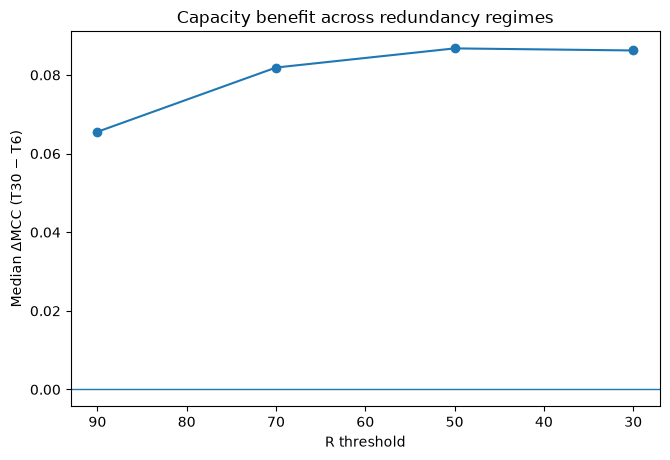

In [13]:
fig, ax = plt.subplots(figsize=(6.8, 4.7))
ax.plot(
    R_LEVELS,
    gain_by_R["median_delta"],
    marker="o",
)
ax.axhline(0, linewidth=1)
ax.set_xlabel("R threshold")
ax.set_ylabel("Median ΔMCC (T30 − T6)")
ax.set_title("Capacity benefit across redundancy regimes")
ax.invert_xaxis()
plt.tight_layout()
plt.show()

# 8. Capacity benefit across homology-separation levels

In [14]:
gain_by_S = (
    mcc_pairs.groupby("S")
    .agg(
        mean_delta=("delta_T30_minus_T6", "mean"),
        median_delta=("delta_T30_minus_T6", "median"),
        fraction_positive=(
            "delta_T30_minus_T6",
            lambda x: (x > 0).mean(),
        ),
        fraction_substantial=(
            "delta_T30_minus_T6",
            lambda x: (x > SUBSTANTIAL_GAIN).mean(),
        ),
    )
    .reindex(S_LEVELS)
)

display(gain_by_S)

,mean_delta,median_delta,fraction_positive,fraction_substantial
S,,,,
90,0.079456,0.069400,0.942857,0.592857
70,0.078637,0.075297,0.907143,0.621429
50,0.082158,0.078380,0.935714,0.621429
30,0.098041,0.090853,0.928571,0.635714


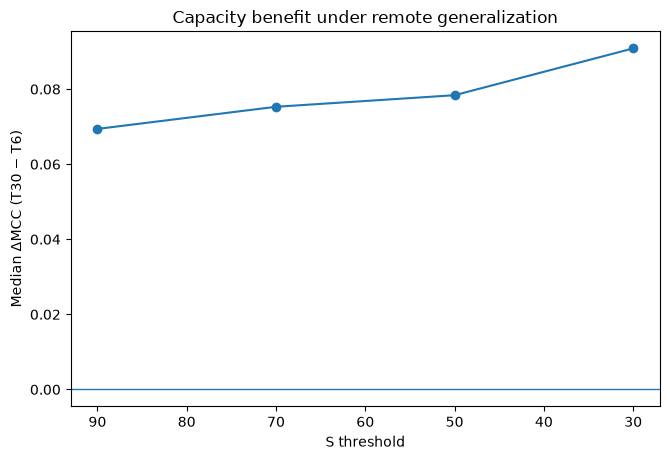

In [15]:
fig, ax = plt.subplots(figsize=(6.8, 4.7))
ax.plot(
    S_LEVELS,
    gain_by_S["median_delta"],
    marker="o",
)
ax.axhline(0, linewidth=1)
ax.set_xlabel("S threshold")
ax.set_ylabel("Median ΔMCC (T30 − T6)")
ax.set_title("Capacity benefit under remote generalization")
ax.invert_xaxis()
plt.tight_layout()
plt.show()

Because native test membership changes with S, the *change in the T30–T6 gap across S* is a landscape-level comparison, not a paired per-protein contrast.

# 9. Full R×S map of the capacity benefit

In [16]:
gain_surface = (
    mcc_pairs.groupby(["R", "S"])[
        "delta_T30_minus_T6"
    ]
    .median()
    .unstack()
    .reindex(index=R_LEVELS, columns=S_LEVELS)
)

display(gain_surface)

S,90,70,50,30
R,,,,
90,0.054476,0.065621,0.066311,0.086473
70,0.080862,0.076281,0.086822,0.091031
50,0.101479,0.090575,0.076996,0.097949
30,0.080158,0.086591,0.081270,0.097520


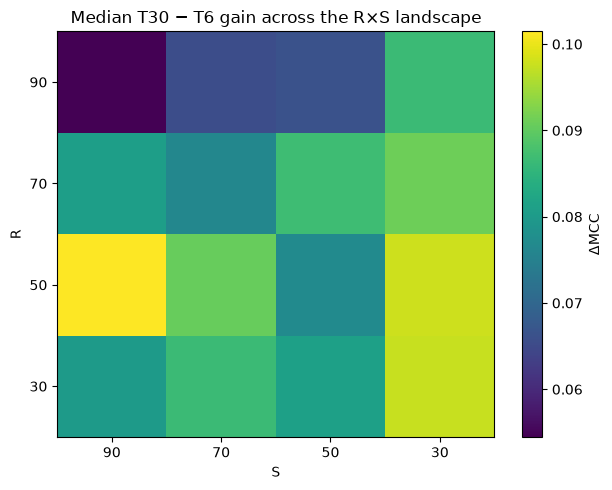

In [17]:
fig, ax = plt.subplots(figsize=(6.3, 5.0))
im = ax.imshow(gain_surface.to_numpy(), aspect="auto")

ax.set_xticks(range(len(S_LEVELS)), S_LEVELS)
ax.set_yticks(range(len(R_LEVELS)), R_LEVELS)
ax.set_xlabel("S")
ax.set_ylabel("R")
ax.set_title("Median T30 − T6 gain across the R×S landscape")
plt.colorbar(im, ax=ax, label="ΔMCC")
plt.tight_layout()
plt.show()

# 10. Permissive versus strict corner

In [18]:
corner_summary = (
    mcc_pairs[
        (
            (mcc_pairs["R"].eq(90) & mcc_pairs["S"].eq(90))
            |
            (mcc_pairs["R"].eq(30) & mcc_pairs["S"].eq(30))
        )
    ]
    .assign(
        corner=lambda x: np.where(
            x["R"].eq(90),
            "R90_S90",
            "R30_S30",
        )
    )
    .groupby("corner")[
        "delta_T30_minus_T6"
    ]
    .agg(
        ["mean", "median", "std", "min", "max"]
    )
)

display(corner_summary)

if {"R90_S90", "R30_S30"} <= set(corner_summary.index):
    print(
        "Strict-minus-permissive change in median T30 benefit:",
        corner_summary.loc["R30_S30", "median"]
        - corner_summary.loc["R90_S90", "median"],
    )

,mean,median,std,min,max
corner,,,,,
R30_S30,0.088075,0.097520,0.070531,-0.012532,0.285764
R90_S90,0.056888,0.054476,0.054055,-0.004128,0.189586


Strict-minus-permissive change in median T30 benefit: 0.04304366548984906


# 11. Does T30 improve worst-case generalization?

In [19]:
surface_wc_rows = []

for keys, grp in plm.groupby(
    ["task", "representation", "algorithm"]
):
    task, rep, alg = keys

    if len(grp) != 16:
        continue

    surface_wc_rows.append(
        {
            "task": task,
            "representation": rep,
            "algorithm": alg,
            "worst_mcc": grp["mcc"].min(),
            "median_mcc": grp["mcc"].median(),
            "best_mcc": grp["mcc"].max(),
            "surface_range": (
                grp["mcc"].max() - grp["mcc"].min()
            ),
        }
    )

surface_wc = pd.DataFrame(surface_wc_rows)

wc_wide = surface_wc.pivot_table(
    index=["task", "algorithm"],
    columns="representation",
    values=[
        "worst_mcc",
        "median_mcc",
        "surface_range",
    ],
    aggfunc="first",
)

wc_compare = pd.DataFrame(index=wc_wide.index)

wc_compare["worst_case_lift_T30_minus_T6"] = (
    wc_wide["worst_mcc"][T30]
    - wc_wide["worst_mcc"][T6]
)

wc_compare["median_surface_lift_T30_minus_T6"] = (
    wc_wide["median_mcc"][T30]
    - wc_wide["median_mcc"][T6]
)

wc_compare["range_reduction_T6_minus_T30"] = (
    wc_wide["surface_range"][T6]
    - wc_wide["surface_range"][T30]
)

wc_compare = wc_compare.reset_index()

display(
    wc_compare[
        [
            "worst_case_lift_T30_minus_T6",
            "median_surface_lift_T30_minus_T6",
            "range_reduction_T6_minus_T30",
        ]
    ].agg(["mean", "median", "std", "min", "max"])
)

,worst_case_lift_T30_minus_T6,median_surface_lift_T30_minus_T6,range_reduction_T6_minus_T30
mean,0.126973,0.081184,0.064653
median,0.109083,0.085725,0.021877
std,0.134790,0.062087,0.109974
min,-0.012532,0.003280,-0.021975
max,0.480903,0.238617,0.398774


A positive `worst_case_lift` means that T30 raises the floor of the complete 16-cell generalization surface.

A positive `range_reduction` means that the T30 surface is flatter than the T6 surface.

# 12. Does increased ESM2 capacity reduce redundancy sensitivity?

In [20]:
r_rows = []

for keys, grp in plm.groupby(
    ["task", "representation", "algorithm", "S"]
):
    task, rep, alg, s = keys

    lookup = dict(zip(grp["R"].astype(int), grp["mcc"]))

    if 90 in lookup and 30 in lookup:
        r_rows.append(
            {
                "task": task,
                "representation": rep,
                "algorithm": alg,
                "S": s,
                "delta_R30_minus_R90": (
                    lookup[30] - lookup[90]
                ),
            }
        )

r_effects = pd.DataFrame(r_rows)

r_wide = r_effects.pivot_table(
    index=["task", "algorithm", "S"],
    columns="representation",
    values="delta_R30_minus_R90",
    aggfunc="first",
).dropna()

r_capacity_robustness = r_wide.reset_index()

r_capacity_robustness["signed_R_effect_T30_minus_T6"] = (
    r_capacity_robustness[T30]
    - r_capacity_robustness[T6]
)

r_capacity_robustness["abs_R_sensitivity_reduction"] = (
    r_capacity_robustness[T6].abs()
    - r_capacity_robustness[T30].abs()
)

display(
    r_capacity_robustness[
        [
            "signed_R_effect_T30_minus_T6",
            "abs_R_sensitivity_reduction",
        ]
    ].agg(["mean", "median", "std", "min", "max"])
)

print(
    "Fraction where T30 has lower absolute R sensitivity:",
    (
        r_capacity_robustness["abs_R_sensitivity_reduction"] > 0
    ).mean(),
)

representation,signed_R_effect_T30_minus_T6,abs_R_sensitivity_reduction
mean,0.000615,0.022082
median,0.005838,0.011006
std,0.068697,0.062617
min,-0.413676,-0.110222
max,0.116278,0.413676


Fraction where T30 has lower absolute R sensitivity: 0.6357142857142857


# 13. Does increased ESM2 capacity reduce S sensitivity?

In [21]:
s_rows = []

for keys, grp in plm.groupby(
    ["task", "representation", "algorithm", "R"]
):
    task, rep, alg, r = keys

    lookup = dict(zip(grp["S"].astype(int), grp["mcc"]))

    if 90 in lookup and 30 in lookup:
        s_rows.append(
            {
                "task": task,
                "representation": rep,
                "algorithm": alg,
                "R": r,
                "delta_S30_minus_S90": (
                    lookup[30] - lookup[90]
                ),
            }
        )

s_effects = pd.DataFrame(s_rows)

s_wide = s_effects.pivot_table(
    index=["task", "algorithm", "R"],
    columns="representation",
    values="delta_S30_minus_S90",
    aggfunc="first",
).dropna()

s_capacity_robustness = s_wide.reset_index()

s_capacity_robustness["signed_S_effect_T30_minus_T6"] = (
    s_capacity_robustness[T30]
    - s_capacity_robustness[T6]
)

s_capacity_robustness["abs_S_sensitivity_reduction"] = (
    s_capacity_robustness[T6].abs()
    - s_capacity_robustness[T30].abs()
)

display(
    s_capacity_robustness[
        [
            "signed_S_effect_T30_minus_T6",
            "abs_S_sensitivity_reduction",
        ]
    ].agg(["mean", "median", "std", "min", "max"])
)

print(
    "Fraction where T30 has lower absolute S sensitivity:",
    (
        s_capacity_robustness["abs_S_sensitivity_reduction"] > 0
    ).mean(),
)

representation,signed_S_effect_T30_minus_T6,abs_S_sensitivity_reduction
mean,0.018586,0.022729
median,0.007262,0.005694
std,0.084764,0.079527
min,-0.263854,-0.154894
max,0.537944,0.537944


Fraction where T30 has lower absolute S sensitivity: 0.65


# 14. Is the T30 gain mainly a headroom effect?

Tasks already close to perfect prediction leave less room for T30 to improve.

Test the descriptive relationship between:

\[
MCC_{T6}
\]

and

\[
\Delta MCC_{T30-T6}.
\]

A negative association is compatible with diminishing returns / saturation.

It does **not** prove that all capacity gains are caused by headroom.

In [22]:
headroom = mcc_pairs[
    ["task", "R", "S", "algorithm", "T6", "delta_T30_minus_T6"]
].copy()

global_rho = (
    headroom["T6"]
    .corr(
        headroom["delta_T30_minus_T6"],
        method="spearman",
    )
)

print(
    "Global Spearman T6 baseline MCC vs T30 gain:",
    global_rho,
)

task_headroom_rows = []

for task, grp in headroom.groupby("task"):
    rho = (
        grp["T6"].corr(
            grp["delta_T30_minus_T6"],
            method="spearman",
        )
        if grp["T6"].nunique() > 1
        else np.nan
    )

    task_headroom_rows.append(
        {
            "task": task,
            "n": len(grp),
            "spearman_rho": rho,
            "median_T6_mcc": grp["T6"].median(),
            "median_T30_gain": (
                grp["delta_T30_minus_T6"].median()
            ),
        }
    )

task_headroom = (
    pd.DataFrame(task_headroom_rows)
    .sort_values("median_T6_mcc", ascending=False)
)

display(task_headroom)

Global Spearman T6 baseline MCC vs T30 gain: -0.8244232094362662


,task,n,spearman_rho,median_T6_mcc,median_T30_gain
1,global_hard,80,-0.076501,0.930180,0.007816
4,subtype_depolymerase,80,-0.746340,0.885816,0.021048
3,multiclass_clean,80,-0.492422,0.844689,0.030146
0,global_easy,80,-0.863549,0.797830,0.113017
2,global_mixed,80,-0.868964,0.791804,0.104026
5,subtype_endolysin,80,-0.940108,0.765725,0.133600
6,subtype_val,80,-0.580360,0.627972,0.121127


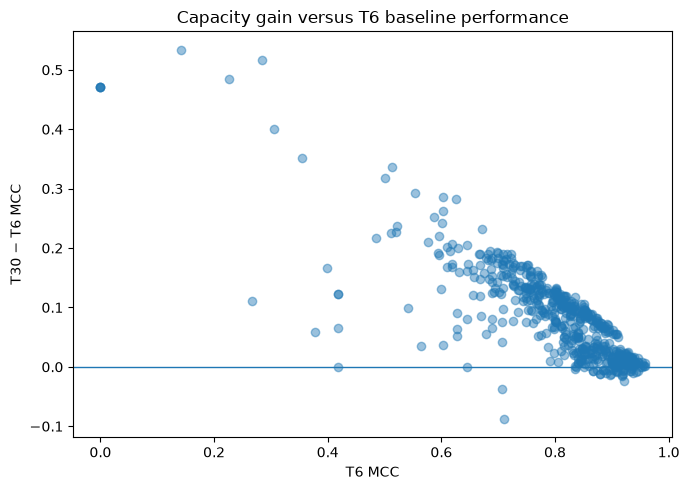

In [23]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(
    headroom["T6"],
    headroom["delta_T30_minus_T6"],
    alpha=0.45,
)
ax.axhline(0, linewidth=1)
ax.set_xlabel("T6 MCC")
ax.set_ylabel("T30 − T6 MCC")
ax.set_title("Capacity gain versus T6 baseline performance")
plt.tight_layout()
plt.show()

# 15. Headroom-normalized gain

In [24]:
# Use only cells with meaningful remaining headroom to avoid unstable ratios.
HEADROOM_MIN = 0.05

headroom["available_headroom"] = 1.0 - headroom["T6"]

headroom["fraction_of_MCC_headroom_recovered"] = np.where(
    headroom["available_headroom"] >= HEADROOM_MIN,
    headroom["delta_T30_minus_T6"]
    / headroom["available_headroom"],
    np.nan,
)

valid = headroom[
    "fraction_of_MCC_headroom_recovered"
].replace([np.inf, -np.inf], np.nan).dropna()

display(
    valid.agg(
        ["count", "mean", "median", "std", "min", "max"]
    ).to_frame("fraction_of_headroom_recovered")
)

display(
    headroom.groupby("task")[
        "fraction_of_MCC_headroom_recovered"
    ]
    .agg(["count", "mean", "median", "std"])
)

,fraction_of_headroom_recovered
count,553.000000
mean,0.370779
median,0.425292
std,0.232593
min,-0.299636
max,0.756306


,count,mean,median,std
task,,,,
global_easy,80,0.564465,0.580245,0.076833
global_hard,73,0.108737,0.127574,0.128714
global_mixed,80,0.546612,0.568087,0.081920
multiclass_clean,80,0.192963,0.204072,0.129519
subtype_depolymerase,80,0.187465,0.186697,0.193105
subtype_endolysin,80,0.582164,0.585745,0.067018
subtype_val,80,0.390118,0.438569,0.217523


This quantity is purely descriptive because MCC is not a linear biological utility scale. It is useful only to distinguish very small absolute gains caused by near-ceiling T6 performance from genuinely weak T30 advantages.

# 16. Where does T6 outperform T30?

In [25]:
t6_better = mcc_pairs[
    mcc_pairs["delta_T30_minus_T6"] < -PRACTICAL_TIE
].copy()

print(
    "Cells where T6 is better by >0.01 MCC:",
    len(t6_better),
    "/",
    len(mcc_pairs),
)

if len(t6_better):
    display(
        t6_better.groupby("task")
        .agg(
            n=("delta_T30_minus_T6", "size"),
            median_delta=("delta_T30_minus_T6", "median"),
            min_delta=("delta_T30_minus_T6", "min"),
            median_T6=("T6", "median"),
        )
        .sort_values("n", ascending=False)
    )

    display(
        pd.crosstab(
            t6_better["R"],
            t6_better["S"],
        )
        .reindex(
            index=R_LEVELS,
            columns=S_LEVELS,
            fill_value=0,
        )
    )

    display(
        t6_better["algorithm"]
        .value_counts()
        .rename("n")
        .to_frame()
    )

Cells where T6 is better by >0.01 MCC: 11 / 560


,n,median_delta,min_delta,median_T6
task,,,,
subtype_depolymerase,5,-0.013479,-0.023111,0.918011
global_hard,2,-0.012431,-0.012532,0.908936
multiclass_clean,2,-0.012765,-0.012765,0.878846
subtype_val,2,-0.061736,-0.086975,0.708024


S,90,70,50,30
R,,,,
90,0,0,0,0
70,0,0,0,1
50,0,2,1,2
30,2,1,1,1


,n
algorithm,
KNN,4
LR,2
MLP,2
RF,2
XGB,1


The purpose is not to explain every exception. It is to determine whether T6 wins form a coherent regime or are sparse exceptions distributed across tasks/algorithms.

# 17. AP-skill capacity benefit

In [26]:
metric_pairs = [mcc_pairs.copy()]

if "ap_skill" in plm.columns:
    ap_pairs = build_t30_t6_pairs(
        plm[plm["task"].isin(BINARY_TASKS)],
        "ap_skill",
    )

    metric_pairs.append(ap_pairs)

    display(
        ap_pairs["delta_T30_minus_T6"]
        .agg(["count", "mean", "median", "std", "min", "max"])
        .to_frame("T30 − T6 AP-skill")
    )

    display(
        ap_pairs.groupby("task")[
            "delta_T30_minus_T6"
        ]
        .agg(
            mean="mean",
            median="median",
            fraction_positive=lambda x: (x > 0).mean(),
        )
    )

,T30 − T6 AP-skill
count,480.000000
mean,0.077440
median,0.062617
std,0.085784
min,-0.068628
max,0.719668


,mean,median,fraction_positive
task,,,
global_easy,0.071947,0.072831,1.0000
global_hard,0.003690,0.003597,0.7750
global_mixed,0.071662,0.067202,1.0000
subtype_depolymerase,0.025170,0.022277,0.9000
subtype_endolysin,0.090285,0.090984,1.0000
subtype_val,0.201889,0.178291,0.9875


# 18. Multiclass macro-F1 capacity benefit

In [27]:
multi_pairs = pd.DataFrame()

if (
    "macro_f1" in plm.columns
    and plm.loc[
        plm["task"].eq("multiclass_clean"),
        "macro_f1",
    ].notna().any()
):
    multi_pairs = build_t30_t6_pairs(
        plm[plm["task"].eq("multiclass_clean")],
        "macro_f1",
    )

    display(
        multi_pairs["delta_T30_minus_T6"]
        .agg(["count", "mean", "median", "std", "min", "max"])
        .to_frame("T30 − T6 macro-F1")
    )

    print(
        "Fraction T30 macro-F1 advantage > 0:",
        (multi_pairs["delta_T30_minus_T6"] > 0).mean(),
    )

,T30 − T6 macro-F1
count,80.000000
mean,0.042035
median,0.043420
std,0.036541
min,-0.045199
max,0.123020


Fraction T30 macro-F1 advantage > 0: 0.875


# 19. Cross-metric agreement

In [28]:
metric_frames = [
    mcc_pairs[
        [
            "task",
            "R",
            "S",
            "algorithm",
            "delta_T30_minus_T6",
        ]
    ].rename(
        columns={
            "delta_T30_minus_T6": "delta_mcc"
        }
    )
]

if "ap_pairs" in globals() and len(ap_pairs):
    metric_frames.append(
        ap_pairs[
            [
                "task",
                "R",
                "S",
                "algorithm",
                "delta_T30_minus_T6",
            ]
        ].rename(
            columns={
                "delta_T30_minus_T6": "delta_ap_skill"
            }
        )
    )

if len(multi_pairs):
    metric_frames.append(
        multi_pairs[
            [
                "task",
                "R",
                "S",
                "algorithm",
                "delta_T30_minus_T6",
            ]
        ].rename(
            columns={
                "delta_T30_minus_T6": "delta_macro_f1"
            }
        )
    )

cross_metric = metric_frames[0].copy()

for frame in metric_frames[1:]:
    cross_metric = cross_metric.merge(
        frame,
        on=["task", "R", "S", "algorithm"],
        how="left",
    )

delta_cols = [
    c for c in [
        "delta_mcc",
        "delta_ap_skill",
        "delta_macro_f1",
    ]
    if c in cross_metric.columns
]

if len(delta_cols) > 1:
    display(
        cross_metric[delta_cols]
        .corr(method="spearman")
    )

,delta_mcc,delta_ap_skill,delta_macro_f1
delta_mcc,1.000000,0.780822,0.663482
delta_ap_skill,0.780822,1.000000,NaN
delta_macro_f1,0.663482,NaN,1.000000


# 20. Compact capacity-regime map

Summarize each `task × R × S` condition across the five algorithms.

This distinguishes:

- conditions where the T30 advantage is algorithm-independent;
- conditions where capacity benefit depends strongly on downstream learner;
- conditions where T6 is effectively sufficient.

In [29]:
regime_map = (
    mcc_pairs.groupby(["task", "R", "S"])
    .agg(
        median_delta=("delta_T30_minus_T6", "median"),
        mean_delta=("delta_T30_minus_T6", "mean"),
        min_delta=("delta_T30_minus_T6", "min"),
        max_delta=("delta_T30_minus_T6", "max"),
        fraction_positive=(
            "delta_T30_minus_T6",
            lambda x: (x > 0).mean(),
        ),
        fraction_gt_001=(
            "delta_T30_minus_T6",
            lambda x: (x > PRACTICAL_TIE).mean(),
        ),
        fraction_gt_005=(
            "delta_T30_minus_T6",
            lambda x: (x > SUBSTANTIAL_GAIN).mean(),
        ),
    )
    .reset_index()
)

regime_map["capacity_regime"] = (
    regime_map["median_delta"]
    .map(classify_capacity_gain)
)

display(
    pd.crosstab(
        regime_map["task"],
        regime_map["capacity_regime"],
        normalize="index",
    )
)

capacity_regime,T30_moderate,T30_substantial,practically_equivalent
task,,,
global_easy,0.0000,1.0,0.0000
global_hard,0.4375,0.0,0.5625
global_mixed,0.0000,1.0,0.0000
multiclass_clean,0.8125,0.0,0.1875
subtype_depolymerase,0.6875,0.0,0.3125
subtype_endolysin,0.0000,1.0,0.0000
subtype_val,0.0000,1.0,0.0000


# 21. RQ7 synthesis

After execution, RQ7 should answer:

1. What is the global paired T30−T6 effect?
2. How often is the gain substantial, moderate, negligible, or reversed?
3. Which tasks benefit most from the larger ESM2 representation?
4. Which tasks are already close to T6 sufficiency?
5. Does the capacity benefit grow under lower R?
6. Does it grow under lower S?
7. Is the strict-corner advantage larger than the permissive-corner advantage?
8. Does T30 raise worst-case performance?
9. Does T30 flatten the 4×4 surface relative to T6?
10. Does T30 reduce absolute R sensitivity?
11. Does T30 reduce absolute S sensitivity?
12. How much of task-to-task heterogeneity is compatible with T6 ceiling/headroom?
13. Are T6 wins concentrated in a coherent regime?
14. Do AP skill and macro-F1 preserve the same conclusion?

The final claim must remain **within-family and benchmark-specific**:

> Larger ESM2 capacity provides additional functional-generalization value in many—but not all—regimes, with the strongest gains expected where the smaller representation has not already saturated the task and where evaluation demands more remote generalization.

In [30]:
summary_rows = []

d = mcc_pairs["delta_T30_minus_T6"]

summary_rows.append(
    {
        "evidence": "global_MCC_capacity_gain",
        "group": "all",
        "n": len(d),
        "mean_delta": d.mean(),
        "median_delta": d.median(),
        "fraction_positive": (d > 0).mean(),
        "fraction_gt_001": (d > PRACTICAL_TIE).mean(),
        "fraction_gt_005": (d > SUBSTANTIAL_GAIN).mean(),
        "fraction_T6_better_gt_001": (
            d < -PRACTICAL_TIE
        ).mean(),
    }
)

for task, row in task_gain.iterrows():
    summary_rows.append(
        {
            "evidence": "MCC_capacity_gain_by_task",
            "group": task,
            "n": row["n"],
            "mean_delta": row["mean_delta"],
            "median_delta": row["median_delta"],
            "fraction_positive": row["fraction_positive"],
            "fraction_gt_005": row["fraction_substantial"],
            "fraction_equivalent": row["fraction_equivalent"],
            "fraction_T6_better_gt_001": row["fraction_T6_better"],
        }
    )

summary_rows.append(
    {
        "evidence": "worst_case_and_surface_stability",
        "group": "all",
        "n": len(wc_compare),
        "median_worst_case_lift": (
            wc_compare[
                "worst_case_lift_T30_minus_T6"
            ].median()
        ),
        "median_surface_range_reduction": (
            wc_compare[
                "range_reduction_T6_minus_T30"
            ].median()
        ),
    }
)

summary_rows.append(
    {
        "evidence": "R_robustness_difference",
        "group": "all",
        "n": len(r_capacity_robustness),
        "median_abs_sensitivity_reduction": (
            r_capacity_robustness[
                "abs_R_sensitivity_reduction"
            ].median()
        ),
        "fraction_T30_less_sensitive": (
            r_capacity_robustness[
                "abs_R_sensitivity_reduction"
            ] > 0
        ).mean(),
    }
)

summary_rows.append(
    {
        "evidence": "S_robustness_difference",
        "group": "all",
        "n": len(s_capacity_robustness),
        "median_abs_sensitivity_reduction": (
            s_capacity_robustness[
                "abs_S_sensitivity_reduction"
            ].median()
        ),
        "fraction_T30_less_sensitive": (
            s_capacity_robustness[
                "abs_S_sensitivity_reduction"
            ] > 0
        ).mean(),
    }
)

summary_rows.append(
    {
        "evidence": "headroom_association",
        "group": "all",
        "n": len(headroom),
        "spearman_T6_MCC_vs_gain": global_rho,
    }
)

rq7_summary = pd.DataFrame(summary_rows)
display(rq7_summary)

,evidence,group,n,mean_delta,median_delta,fraction_positive,fraction_gt_001,fraction_gt_005,fraction_T6_better_gt_001,fraction_equivalent,median_worst_case_lift,median_surface_range_reduction,median_abs_sensitivity_reduction,fraction_T30_less_sensitive,spearman_T6_MCC_vs_gain
0,global_MCC_capacity_gain,all,560.0,0.084573,0.076907,0.928571,0.828571,0.617857,0.019643,NaN,NaN,NaN,NaN,NaN,NaN
1,MCC_capacity_gain_by_task,subtype_endolysin,80.0,0.132807,0.133600,1.000000,NaN,0.987500,0.000000,0.0000,NaN,NaN,NaN,NaN,NaN
2,MCC_capacity_gain_by_task,subtype_val,80.0,0.164512,0.121127,0.937500,NaN,0.887500,0.025000,0.0375,NaN,NaN,NaN,NaN,NaN
3,MCC_capacity_gain_by_task,global_easy,80.0,0.113703,0.113017,1.000000,NaN,1.000000,0.000000,0.0000,NaN,NaN,NaN,NaN,NaN
4,MCC_capacity_gain_by_task,global_mixed,80.0,0.113086,0.104026,1.000000,NaN,1.000000,0.000000,0.0000,NaN,NaN,NaN,NaN,NaN
5,MCC_capacity_gain_by_task,multiclass_clean,80.0,0.031465,0.030146,0.925000,NaN,0.225000,0.025000,0.1875,NaN,NaN,NaN,NaN,NaN
6,MCC_capacity_gain_by_task,subtype_depolymerase,80.0,0.028987,0.021048,0.837500,NaN,0.225000,0.062500,0.2750,NaN,NaN,NaN,NaN,NaN
7,MCC_capacity_gain_by_task,global_hard,80.0,0.007452,0.007816,0.800000,NaN,0.000000,0.025000,0.5625,NaN,NaN,NaN,NaN,NaN
8,worst_case_and_surface_stability,all,35.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.109083,0.021877,NaN,NaN,NaN
9,R_robustness_difference,all,140.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.011006,0.635714,NaN


In [31]:
SUMMARY_PATH = CACHE_DIR / "rq7_evidence_summary.tsv"
PAIR_PATH = CACHE_DIR / "rq7_t30_vs_t6_mcc.tsv"
TASK_PATH = CACHE_DIR / "rq7_t30_vs_t6_by_task.tsv"
SURFACE_PATH = CACHE_DIR / "rq7_t30_vs_t6_gain_surface.tsv"
WC_PATH = CACHE_DIR / "rq7_t30_vs_t6_worst_case.tsv"
RROB_PATH = CACHE_DIR / "rq7_t30_vs_t6_R_robustness.tsv"
SROB_PATH = CACHE_DIR / "rq7_t30_vs_t6_S_robustness.tsv"
HEADROOM_PATH = CACHE_DIR / "rq7_t30_vs_t6_headroom.tsv"
REGIME_PATH = CACHE_DIR / "rq7_capacity_regime_map.tsv"
CROSSMETRIC_PATH = CACHE_DIR / "rq7_cross_metric_capacity_gains.tsv"

rq7_summary.to_csv(SUMMARY_PATH, sep="\t", index=False)
mcc_pairs.to_csv(PAIR_PATH, sep="\t", index=False)
task_gain.reset_index().to_csv(TASK_PATH, sep="\t", index=False)
gain_surface.to_csv(SURFACE_PATH, sep="\t")
wc_compare.to_csv(WC_PATH, sep="\t", index=False)
r_capacity_robustness.to_csv(RROB_PATH, sep="\t", index=False)
s_capacity_robustness.to_csv(SROB_PATH, sep="\t", index=False)
headroom.to_csv(HEADROOM_PATH, sep="\t", index=False)
regime_map.to_csv(REGIME_PATH, sep="\t", index=False)
cross_metric.to_csv(CROSSMETRIC_PATH, sep="\t", index=False)

print("Saved:")
for p in [
    SUMMARY_PATH,
    PAIR_PATH,
    TASK_PATH,
    SURFACE_PATH,
    WC_PATH,
    RROB_PATH,
    SROB_PATH,
    HEADROOM_PATH,
    REGIME_PATH,
    CROSSMETRIC_PATH,
]:
    print(" ", p)

Saved:
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq7_evidence_summary.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq7_t30_vs_t6_mcc.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq7_t30_vs_t6_by_task.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq7_t30_vs_t6_gain_surface.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq7_t30_vs_t6_worst_case.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq7_t30_vs_t6_R_robustness.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/ana

## Interpretation guardrails

- This is a **T30-versus-T6 capacity contrast within the ESM2 family**, not a universal scaling law.
- The two variants differ in pretrained parameter count, depth/architecture, and embedding dimension; the benchmark cannot attribute the downstream gain to parameter count alone.
- T6 sufficiency means practical equivalence on the current downstream benchmark, not equivalence of the underlying representations.
- A negative correlation between T6 baseline MCC and T30 gain is compatible with saturation/headroom but does not prove a causal ceiling mechanism.
- Native changes across R/S characterize the factorial landscape; common-test paired sensitivity comes later.
- VAL remains support-limited and should not drive global scaling conclusions.
- Compute cost is intentionally deferred to the compute RQ.